# 1. Data cleaning and relevance filtering

| | |
|---|---|
| **Reads** | df_news_AI.parquet (raw scraped articles, see data/README.md) |
| **Writes** | df_news_clean.parquet |
| **Next** | 02_topic_modeling.ipynb |

**Paths:** the first code cell defines DATA_DIR: a Google Drive folder when running in Colab, <repo>/data/ when running locally (start Jupyter from the notebooks/ folder).

## 1. Packages

In [1]:
# Basic imports
import pandas as pd
import matplotlib.pyplot as plt
# For text processing and metrics
import re
from sklearn.metrics.pairwise import cosine_similarity

# Model
from sentence_transformers import SentenceTransformer

In [ ]:
# ---- Environment setup: works in Google Colab and locally ----
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    # Google Drive folder that holds the intermediate files (change it if yours is different)
    DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Final Project NLP"
except ImportError:
    # Local run: intermediate files live in <repo>/data/ (start Jupyter from notebooks/)
    DATA_DIR = str(Path.cwd().parent / "data")
Path(DATA_DIR).mkdir(parents=True, exist_ok=True)
print("DATA_DIR =", DATA_DIR)


## 2. Read data

In [3]:
df_news_AI = pd.read_parquet(f'{DATA_DIR}/df_news_AI.parquet', engine='pyarrow')

In [4]:
display(df_news_AI.head(10))

,url,date,language,title,text
0,https://blockworks.co/price/bad,2025-06-23,en,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod..."
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,en,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,en,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -..."
3,https://citylife.capetown/gl/uncategorized/the...,2023-11-10,en,The Road Ahead: How China's AI Foundation Mode...,The Road Ahead: How China's AI Foundation M...
4,https://citylife.capetown/kk/uncategorized/mic...,2023-11-19,en,Microsoft and Nvidia to Empower Developers wit...,Microsoft and Nvidia to Empower Developers ...
5,https://citylife.capetown/lb/uncategorized/how...,2023-12-12,en,Google Releases New Chatbot Bard as a Strong C...,Google Releases New Chatbot Bard as a Strong ...
6,https://citylife.capetown/technology/zoom-laun...,2023-09-07,en,Zoom Expands AI Offering with AI Companion and...,Zoom Expands AI Offering with AI Companion an...
7,https://citylife.capetown/uncategorized/pro-ai...,2023-08-04,en,Pro-AI Thinking: Enhancing Industrial Environm...,\n\nPro-AI Thinking: Enhancing Industrial Envi...
8,https://clickup.com/ai/prompts/business-risk-m...,2024-03-13,en,Best AI Prompts for Business Risk Management,Best AI Prompts for Business Risk ManagementPr...
9,https://crooksandliars.com/2025/12/state-ags-w...,2025-12-15,en,State AGs Warn AI Companies: Clean Up Your Chi...,\nState AGs Warn AI Companies: Clean Up Your C...


In [5]:
print('Initial dataframe shape :', df_news_AI.shape)
print('Columns in the dataframe :', df_news_AI.columns)

Initial dataframe shape : (199989, 5)
Columns in the dataframe : Index(['url', 'date', 'language', 'title', 'text'], dtype='object')


In [6]:
display(df_news_AI.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199989 entries, 0 to 199988
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   url       199989 non-null  object
 1   date      199989 non-null  object
 2   language  199989 non-null  object
 3   title     199989 non-null  object
 4   text      199989 non-null  object
dtypes: object(5)
memory usage: 7.6+ MB


None

Not null values

In [7]:
# Transform the date column to datetime format
df_news_AI['date'] = pd.to_datetime(df_news_AI['date'])

In [8]:
# Obtain year and month from the date column
df_news_AI['year'] = df_news_AI['date'].dt.year
df_news_AI['month'] = df_news_AI['date'].dt.month

In [9]:
display(df_news_AI.head())

,url,date,language,title,text,year,month
0,https://blockworks.co/price/bad,2025-06-23,en,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod...",2025,6
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,en,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...,2024,7
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,en,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -...",2024,9
3,https://citylife.capetown/gl/uncategorized/the...,2023-11-10,en,The Road Ahead: How China's AI Foundation Mode...,The Road Ahead: How China's AI Foundation M...,2023,11
4,https://citylife.capetown/kk/uncategorized/mic...,2023-11-19,en,Microsoft and Nvidia to Empower Developers wit...,Microsoft and Nvidia to Empower Developers ...,2023,11


Total number of articles: 199989


,year,article_count,%article_count
0,2022,18361,9.0
1,2023,71383,36.0
2,2024,49789,25.0
3,2025,54345,27.0
4,2026,6111,3.0


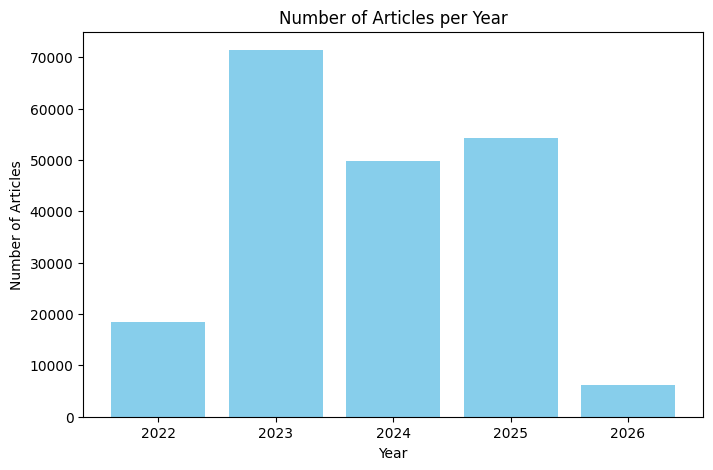

In [10]:
# Check the total number of articles per year
df_aux = df_news_AI.groupby('year')[['url']].count().reset_index()
df_aux = df_aux.rename(columns={'url': 'article_count'})
total_articles = df_aux['article_count'].sum()
df_aux['%article_count'] = round(df_aux['article_count'] / total_articles,2) * 100
print('Total number of articles:', total_articles)
display(df_aux)


# Create plot of article count per year
plt.figure(figsize=(8, 5))
plt.bar(df_aux['year'], df_aux['article_count'], color='skyblue')
plt.xlabel('Year')
plt.ylabel('Number of Articles')
plt.title('Number of Articles per Year')
plt.show()

In [11]:
df_aux = df_news_AI[df_news_AI['year'] == 2026]
df_aux['month'].value_counts()

,count
month,
1,4583
2,1528


In [12]:
# Check the number of words in the title column
df_news_AI['text_word_count'] = df_news_AI['text'].apply(lambda x: len(x.split()))
df_news_AI['title_word_count'] = df_news_AI['title'].apply(lambda x: len(x.split()))

print('Average number of words in the text:', df_news_AI['text_word_count'].mean())
print('Average number of words in the title:', df_news_AI['title_word_count'].mean())

Average number of words in the text: 1231.988419363065
Average number of words in the title: 13.871962957962689


In [13]:
print('Describe title word count:')
print(df_news_AI['title_word_count'].describe())

print('Describe text word count:')
print(df_news_AI['text_word_count'].describe())

Describe title word count:
count    199989.000000
mean         13.871963
std           5.911542
min           1.000000
25%          11.000000
50%          13.000000
75%          16.000000
max        1325.000000
Name: title_word_count, dtype: float64
Describe text word count:
count    199989.000000
mean       1231.988419
std         963.096173
min           4.000000
25%         704.000000
50%        1034.000000
75%        1548.000000
max       39964.000000
Name: text_word_count, dtype: float64


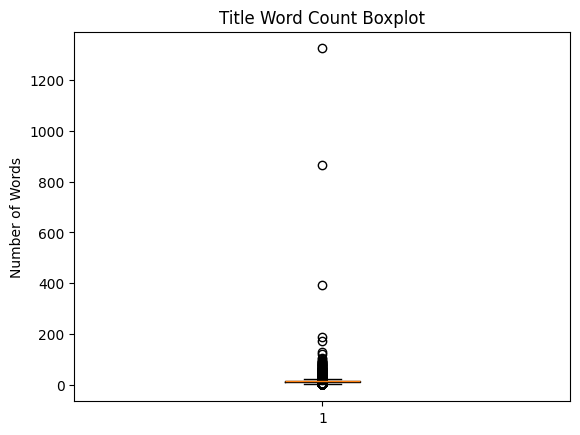

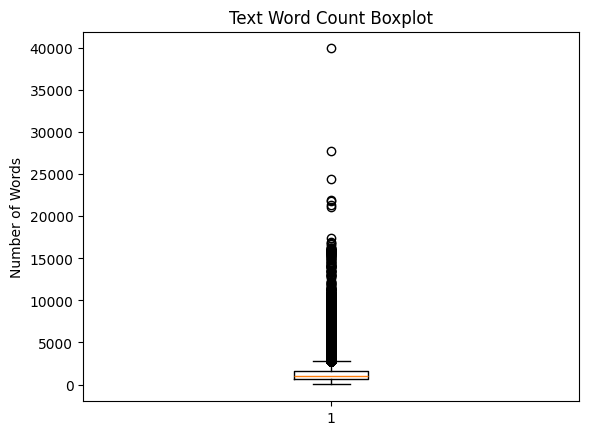

In [14]:
plt.boxplot(df_news_AI['title_word_count'], label='Title Word Count')
plt.title('Title Word Count Boxplot')
plt.ylabel('Number of Words')
plt.show()

plt.boxplot(df_news_AI['text_word_count'], label='Text Word Count')
plt.title('Text Word Count Boxplot')
plt.ylabel('Number of Words')
plt.show()

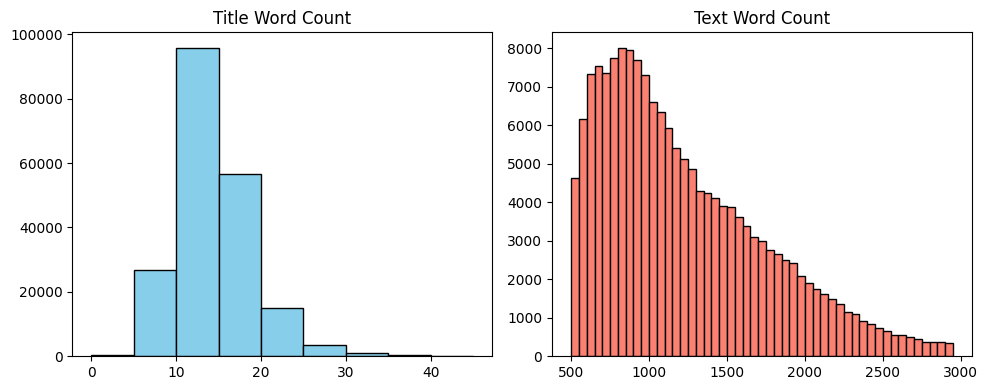

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# First subplot
ax1.hist(df_news_AI['title_word_count'], bins=range(0, 50, 5), color='skyblue', edgecolor='black')
ax1.set_title('Title Word Count')

# Second subplot
ax2.hist(df_news_AI['text_word_count'], bins=range(500, 3000, 50), color='salmon', edgecolor='black')
ax2.set_title('Text Word Count')

plt.tight_layout()
plt.show()

## 3. Clean data

### 3.1 Clean title

In [16]:
df_news_AI.loc[15, 'url']

'https://fedtechmagazine.com/article/2025/01/4-principles-help-federal-agencies-adopt-ai-ethically-and-securely'

In [17]:
df_news_AI['language'].value_counts()

,count
language,
en,199989


In [18]:
# Drop the 'language' column as all the records have the same value 'en' for English
df_news_AI = df_news_AI.drop(columns=['language'])

In [19]:
# Print sample of title 5 sample fo titles from the dataframe
print('Sample title 1:', df_news_AI.loc[15,'title'])
print('Sample title 2:', df_news_AI.loc[7,'title'])
print('Sample title 3:', df_news_AI.loc[12,'title'])
print('Sample title 4:', df_news_AI.loc[1432,'title'])
print('Sample title 5:', df_news_AI.loc[3838,'title'])

Sample title 1: 4 Principles to Help Federal Agencies Adopt AI Ethically and Securely | FedTech Magazine
Sample title 2: Pro-AI Thinking: Enhancing Industrial Environments with Artificial Intelligence
Sample title 3: IIM Ahmedabad student writes project using ChatGPT, scores A+: Sparks debate on AI, effort and what ‘real learning’ means today - The Economic Times
Sample title 4: Orca AI Secures $72.5 Million Investment to Scale Autonomous Shipping Solutions
Sample title 5: OpenAI: OpenAI working with ex-Twitter India head to navigate AI landscape: report - The Economic Times


In [20]:
# We are going to remove title from the text column to title the information more easily
def remove_title_from_text(row):
    title = row['title']
    text = row['text']
    # Remove the title from the text using regex
    cleaned_text = re.sub(re.escape(title), '', text, flags=re.IGNORECASE)
    return cleaned_text.strip()
# Apply the function to the dataframe
#df_news_AI['text'] = df_news_AI.apply(remove_title_from_text, axis=1)

In [21]:
# Remove when the new source for the title using regex
#pattern = r'^(.+?)(?:\s*[|-]\s*.*)?$' # '(.*?)\s*(?:\||-)
def clean_title(title):
    '''
    Cleans the title by removing source information after " | " or " - "
    Parameters:
        title (str): The original title string
    Returns:
        str: The cleaned title string
    '''
    # Remove source after " | "
    title = re.sub(r'\s\|\s.*$', '', title)

    # Remove source after " - "
    title = re.sub(r'\s-\s.*$', '', title)

    return title.strip()

# Display of title samples before cleaning
print('Before cleaning:')
print('Sample title 1:', df_news_AI.loc[15,'title'])
print('Sample title 2:', df_news_AI.loc[7,'title'])
print('Sample title 3:', df_news_AI.loc[12,'title'])
print('Sample title 4:', df_news_AI.loc[1432,'title'])
print('Sample title 5:', df_news_AI.loc[3838,'title'])

# Call the function to clean the title column
df_news_AI["clean_title"] = df_news_AI["title"].apply(lambda row: clean_title(row))
# Unify apostrophes in the title column
df_news_AI['clean_title'] = df_news_AI['clean_title'].replace('’', "'", regex=True)
df_news_AI['clean_title'] = df_news_AI['clean_title'].replace('‘', "'", regex=True)

# Display of title samples after cleaning
print('\nAfter cleaning:')
print('Sample title 1:', df_news_AI.loc[15,'clean_title'])
print('Sample title 2:', df_news_AI.loc[7,'clean_title'])
print('Sample title 3:', df_news_AI.loc[12,'clean_title'])
print('Sample title 4:', df_news_AI.loc[1432,'clean_title'])
print('Sample title 5:', df_news_AI.loc[3838,'clean_title'])


Before cleaning:
Sample title 1: 4 Principles to Help Federal Agencies Adopt AI Ethically and Securely | FedTech Magazine
Sample title 2: Pro-AI Thinking: Enhancing Industrial Environments with Artificial Intelligence
Sample title 3: IIM Ahmedabad student writes project using ChatGPT, scores A+: Sparks debate on AI, effort and what ‘real learning’ means today - The Economic Times
Sample title 4: Orca AI Secures $72.5 Million Investment to Scale Autonomous Shipping Solutions
Sample title 5: OpenAI: OpenAI working with ex-Twitter India head to navigate AI landscape: report - The Economic Times

After cleaning:
Sample title 1: 4 Principles to Help Federal Agencies Adopt AI Ethically and Securely
Sample title 2: Pro-AI Thinking: Enhancing Industrial Environments with Artificial Intelligence
Sample title 3: IIM Ahmedabad student writes project using ChatGPT, scores A+: Sparks debate on AI, effort and what 'real learning' means today
Sample title 4: Orca AI Secures $72.5 Million Investment t

In [22]:
# Add manual modification to a title that is not correctly with the article title
df_news_AI.loc[111391,'clean_title'] = 'Another Minneapolis software business acquired for its AI technology'

### 3.1 Clean text

In [23]:
index = [15, 7, 12, 1432, 3838, 123, 621, 429, 42, 47324]
conta = 1
for i in index:
    print(f'Sample text {conta}:', df_news_AI.loc[i,'title'])
    print(f'Sample text {conta}:', df_news_AI.loc[i,'url'])
    #print(f'Sample text {conta}:', df_news_AI.loc[i,'text'][0:200])
    conta += 1
    print('\n\n')

Sample text 1: 4 Principles to Help Federal Agencies Adopt AI Ethically and Securely | FedTech Magazine
Sample text 1: https://fedtechmagazine.com/article/2025/01/4-principles-help-federal-agencies-adopt-ai-ethically-and-securely



Sample text 2: Pro-AI Thinking: Enhancing Industrial Environments with Artificial Intelligence
Sample text 2: https://citylife.capetown/uncategorized/pro-ai-thinking-unlocking-the-transformative-power-of-ai-in-industrial-environments/319591/



Sample text 3: IIM Ahmedabad student writes project using ChatGPT, scores A+: Sparks debate on AI, effort and what ‘real learning’ means today - The Economic Times
Sample text 3: https://economictimes.indiatimes.com/magazines/panache/iim-ahmedabad-student-writes-project-using-chatgpt-scores-a-sparks-debate-on-ai-effort-and-what-real-learning-means-today/articleshow/120870263.cms



Sample text 4: Orca AI Secures $72.5 Million Investment to Scale Autonomous Shipping Solutions
Sample text 4: https://www.finanznachricht

In [24]:
text = '    Skip to main content \n \n     Skip to search  \n La play  '
result = re.sub(r'\s*\n\s*', '\n', text)
#result = re.sub(r'\n[^\S\r\n]+', '\n', result)
result = re.sub(r'[^\S\r\n]+', ' ', result)
result = result.strip()
print(result)

Skip to main content
Skip to search
La play


In [25]:
# Remove extra newlines, only keep one new line (/n) space
df_news_AI['clean_text'] = df_news_AI['text'].replace(r'\s*\n\s*', '\n', regex=True)
# Remove tabs and multiple white spaces, only keep a single white space
df_news_AI['clean_text'] = df_news_AI['clean_text'].replace(r'[^\S\r\n]+', ' ', regex=True)

In [26]:
# Unify apostrophes
df_news_AI['clean_text'] = df_news_AI['clean_text'].replace('’', "'", regex=True)
df_news_AI['clean_text'] = df_news_AI['clean_text'].replace('‘', "'", regex=True)

Remove content releated to other articles, sources, and videos

In [27]:
def truncate_boilerplate(text):

    # Define your list of "stop" phrases (\b (word boundary) so we don't accidentally match part of a larger word)
    phrases = [
        r"\bmore stories\b",
        r"\bmore on\b",
        r"\bmore from Star Tribune\b",
        r"\brelated topics\b",
        r"\blatest shows\b",
        r"\bpost navigation\b",
        r"\brelated articles\b",
        r"\bread next\b",
        r"\bread more\b",
        r"\byou may also like\b",
        r"\bread more news\b",
        r"\bDon't miss out on ET Prime stories\b",
        r"\bget your daily dose of business updates\b",
        r'\bview comments recommended\b',
        r'\bSee all comments\b',
        r'\bsubscribe to\b',
        r'\bsubscribe for updates\b',
        r'\brecommended stories\b',
        r'\balso from this source\b'
    ]

    # Combine them into one Regex pattern with OR (|) logic
    pattern = "|".join(phrases)

    #  Split the text at the first occurrence (case-insensitive)
    cleaned_text = re.split(pattern, text, flags=re.IGNORECASE)[0]

    # 5. Return the cleaned text, stripping any trailing spaces or newlines
    return cleaned_text.strip()

# Apply the function to your existing DataFrame
# This creates a new column so you don't overwrite your original data just yet!
df_news_AI['clean_text'] = df_news_AI['clean_text'].apply(truncate_boilerplate)

In [28]:
#print(f'Sample text {conta}:', df_news_AI.loc[111391,'title'])
#print(f'Sample text {conta}:', df_news_AI.loc[111391,'clean_title'])
#print(f'Sample text {conta}:', df_news_AI.loc[111391,'url'])
#print(f'Sample text {conta}:', df_news_AI.loc[111391,'clean_text'])
#conta += 1
#print('\n\n\n')

Remove content before the main title

In [29]:
# Remove by default the first line that have the original title in the text, to only consider the title where it is mentioned in the text
for i in range(len(df_news_AI)):
    df_news_AI.loc[i,'clean_text'] = df_news_AI.loc[i,'clean_text'].replace(df_news_AI.loc[i,'title'], '', 1)

In [30]:
# Clean the first part of the text by removing everything before the title
for i in df_news_AI.index:
    title = df_news_AI.loc[i,'clean_title']
    text = df_news_AI.loc[i,'clean_text']

    # Clean the inital part of the text
    # Explict uisng the title to remove unnecessary information from the text (Menu, options, etc.)
    text_split = text.split(title)
    # Select the part after the split that contain the main information, in case the article does not a title in the text, we will keep the original text

    if(len(text_split) > 1):
        # If the title is mentioned several times keep the last part mentioned, that will be the most likely the begining of the article
        main_text = text_split[len(text_split)-1]
    else:
        main_text = text_split[0]

    # Select the text part that is the longest after splitting by the title, as it is more likely to be the main content of the article,
    # Save the cleaned text back to the dataframe
    df_news_AI.loc[i,'clean_text'] = main_text

In [31]:
index = [15, 7, 12, 1432, 3838, 123, 621, 429, 42, 47324]
conta = 1
for i in index:
    print(f'Sample text {conta}:', df_news_AI.loc[i,'clean_title'])
    print(f'Sample text {conta}:', df_news_AI.loc[i,'url'])
    print(f'Sample text {conta}:', df_news_AI.loc[i,'clean_text'][0:300])
    conta += 1
    print('\n\n\n')

Sample text 1: 4 Principles to Help Federal Agencies Adopt AI Ethically and Securely
Sample text 1: https://fedtechmagazine.com/article/2025/01/4-principles-help-federal-agencies-adopt-ai-ethically-and-securely
Sample text 1: 
In a white paper, SolarWinds frames the challenge in terms of privacy, accountability, transparency and simplicity.
by Tanya Candia
Tanya Candia is an international management expert, specializing for more than 25 years in information security strategy and communication for public- and private-sect




Sample text 2: Pro-AI Thinking: Enhancing Industrial Environments with Artificial Intelligence
Sample text 2: https://citylife.capetown/uncategorized/pro-ai-thinking-unlocking-the-transformative-power-of-ai-in-industrial-environments/319591/
Sample text 2: 
ByMampho Brescia
Aug 4, 2023
In the rapidly developing industrial landscape, a paradigm shift called Pro-AI thinking is revolutionizing the way industries operate. This approach combines the innovative and creat

In [32]:
# Check the number of words in the title column
df_news_AI['title_word_clean_count'] = df_news_AI['clean_title'].apply(lambda x: len(x.split()))
df_news_AI['text_word_clean_count'] = df_news_AI['clean_text'].apply(lambda x: len(x.split()))

print('Average number of words in the title:', df_news_AI['title_word_clean_count'].mean())
print('Average number of words in the text:', df_news_AI['text_word_clean_count'].mean())

Average number of words in the title: 11.702338628624574
Average number of words in the text: 757.0671786948283


## 4. Filter articles

In [33]:
# Join title and text columns and do count number of words
df_news_AI['title_text_clean'] = df_news_AI['clean_title'] + ' ' + df_news_AI['clean_text']
df_news_AI['title_text_clean_count'] = df_news_AI['title_text_clean'].apply(lambda x: len(x.split()))

In [34]:
print('Describe title word count:')
print(df_news_AI['title_word_clean_count'].describe())

print('Describe text word count:')
print(df_news_AI['text_word_clean_count'].describe())

print('Describe text word count:')
print(df_news_AI['title_text_clean_count'].describe())

Describe title word count:
count    199989.000000
mean         11.702339
std           5.076872
min           1.000000
25%           9.000000
50%          11.000000
75%          14.000000
max         861.000000
Name: title_word_clean_count, dtype: float64
Describe text word count:
count    199989.000000
mean        757.067179
std         792.681166
min           0.000000
25%         319.000000
50%         618.000000
75%         967.000000
max       27718.000000
Name: text_word_clean_count, dtype: float64
Describe text word count:
count    199989.000000
mean        768.769517
std         793.298520
min           1.000000
25%         331.000000
50%         631.000000
75%         980.000000
max       27739.000000
Name: title_text_clean_count, dtype: float64


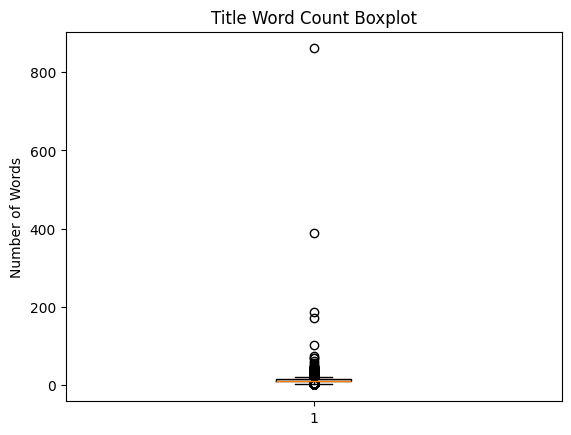

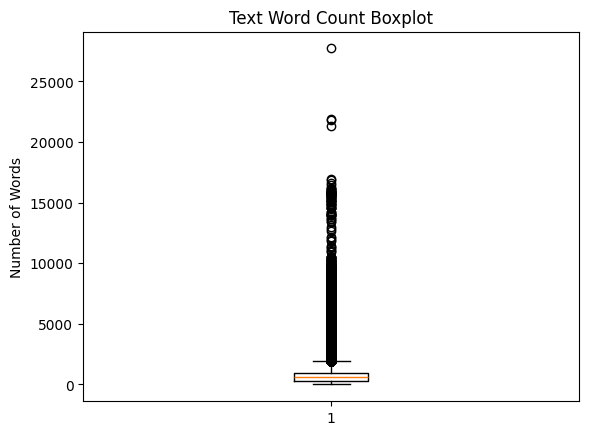

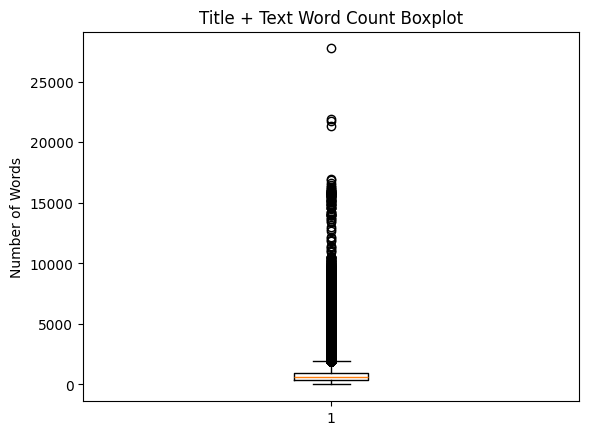

In [35]:
plt.boxplot(df_news_AI['title_word_clean_count'], label='Title Word Count')
plt.title('Title Word Count Boxplot')
plt.ylabel('Number of Words')
plt.show()

plt.boxplot(df_news_AI['text_word_clean_count'], label='Text Word Count')
plt.title('Text Word Count Boxplot')
plt.ylabel('Number of Words')
plt.show()

plt.boxplot(df_news_AI['title_text_clean_count'], label='Title + Text Word Count')
plt.title('Title + Text Word Count Boxplot')
plt.ylabel('Number of Words')
plt.show()

In [36]:
df_aux = df_news_AI[df_news_AI['title_text_clean_count'] >= 50]
print(df_aux['title_text_clean_count'].describe())

count    186029.000000
mean        824.384693
std         795.128662
min          50.000000
25%         411.000000
50%         672.000000
75%        1016.000000
max       27739.000000
Name: title_text_clean_count, dtype: float64


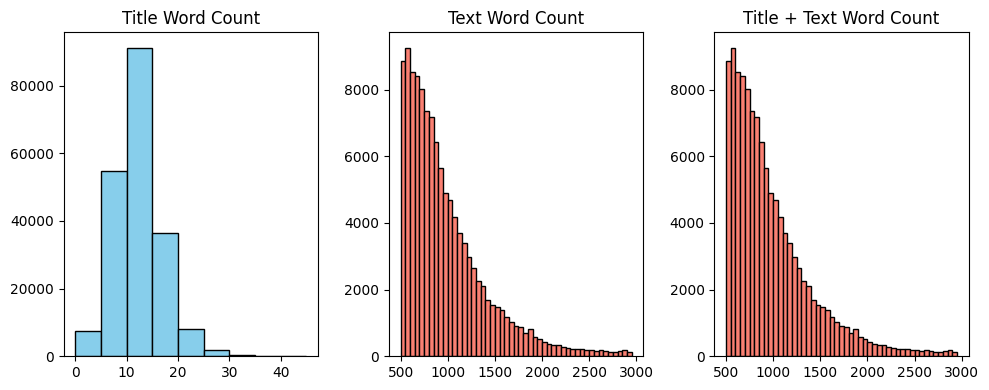

In [37]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 4))

# First subplot
ax1.hist(df_news_AI['title_word_clean_count'], bins=range(0, 50, 5), color='skyblue', edgecolor='black')
ax1.set_title('Title Word Count')

# Second subplot
ax2.hist(df_news_AI['text_word_clean_count'], bins=range(500, 3000, 50), color='salmon', edgecolor='black')
ax2.set_title('Text Word Count')

# Third subplot
ax3.hist(df_news_AI['text_word_clean_count'], bins=range(500, 3000, 50), color='salmon', edgecolor='black')
ax3.set_title('Title + Text Word Count')

plt.tight_layout()
plt.show()

In [38]:
# Imagane url not revant
df_news_AI.loc[2227,'url']

'https://www.rawpixel.com/image/12203262/photo-image-plant-living-room-wooden'

In [39]:
df_news_AI[df_news_AI['title_text_clean_count']==150].head(3)

,url,date,title,text,year,month,text_word_count,title_word_count,clean_title,clean_text,title_word_clean_count,text_word_clean_count,title_text_clean,title_text_clean_count
2823,https://www.freepressjournal.in/ampstories/lif...,2023-06-01,Elon Musk as a DESI groom? Artist generates AI...,\n\nElon Musk as a DESI groom? Artist generate...,2023,6,166,16,Elon Musk as a DESI groom? Artist generates AI...,"\nBy: FPJ Web Desk | June 01, 2023\nElon Musk,...",16,134,Elon Musk as a DESI groom? Artist generates AI...,150
4360,https://www.hindustantimes.com/business/openai...,2024-07-31,OpenAI starts roll-out of advanced voice mode ...,\n\n \n\nOpenAI starts roll-out of advanced vo...,2024,7,1467,16,OpenAI starts roll-out of advanced voice mode ...,"Reuters | Jul 31, 2024 08:34 AM IST Read this...",13,137,OpenAI starts roll-out of advanced voice mode ...,150
5415,https://www.fiercepharma.com/marketing/amgen-l...,2022-07-08,"Amgen showcases its scientists, AI advances in...","\nAmgen showcases its scientists, AI advances ...",2022,7,150,9,"Amgen showcases its scientists, AI advances in...",\nFierce Pharma\nFierce Biotech\nFierce Health...,9,141,"Amgen showcases its scientists, AI advances in...",150


In [40]:
original_rows = df_news_AI.shape[0]
# Filter out articles with text word count less than 50 with less than 50 words
df_news_AI = df_news_AI[df_news_AI['title_text_clean_count'] >= 50]
filtered_rows_1 = df_news_AI.shape[0]
print('Number of rows before filtering:', original_rows)
print('Number of rows after filtering:', filtered_rows_1)
print('Number of rows removed {} , which represents {:.2%}'.format(original_rows - filtered_rows_1, (original_rows - filtered_rows_1) / original_rows))

Number of rows before filtering: 199989
Number of rows after filtering: 186029
Number of rows removed 13960 , which represents 6.98%


In [41]:
# Reset index in the dataframe
#df_news_AI.reset_index(drop=True, inplace=True)

In [42]:
display(df_news_AI.head())

,url,date,title,text,year,month,text_word_count,title_word_count,clean_title,clean_text,title_word_clean_count,text_word_clean_count,title_text_clean,title_text_clean_count
0,https://blockworks.co/price/bad,2025-06-23,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod...",2025,6,483,14,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",Open menuBrandsnewsletterspodcastseventsroundt...,12,470,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",482
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...,2024,7,812,15,This AI video of gymnastics might be the freak...,"\nJennifer Sandlin\n5:13 am Mon\nJul 1, 2024\n...",12,724,This AI video of gymnastics might be the freak...,736
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -...",2024,9,884,12,"If using AI feels like a chore, try this","\nBoing Boing's Shop\n8:00 am Wed\nSep 18, 202...",9,802,"If using AI feels like a chore, try this \nBoi...",811
3,https://citylife.capetown/gl/uncategorized/the...,2023-11-10,The Road Ahead: How China's AI Foundation Mode...,The Road Ahead: How China's AI Foundation M...,2023,11,596,16,The Road Ahead: How China's AI Foundation Mode...,\nIr ao contidoVen. 10 de novembro de 2023 Vid...,16,580,The Road Ahead: How China's AI Foundation Mode...,596
4,https://citylife.capetown/kk/uncategorized/mic...,2023-11-19,Microsoft and Nvidia to Empower Developers wit...,Microsoft and Nvidia to Empower Developers ...,2023,11,622,10,Microsoft and Nvidia to Empower Developers wit...,"\nByМамфо Брешиа\nҚараша 15, 2023\nMicrosoft a...",10,587,Microsoft and Nvidia to Empower Developers wit...,597


In [43]:
df_news_AI.sample(10)['title']

,title
44902,ChatGPT iOS app vs website: 10 key differences...
3558,Top 5 free AI art generators of 2023
134183,Tensor Processing Unit (TPU) Market Set To Hit...
128478,ChatGPT Pro seems imminent as some users get i...
68858,Meta’s 'Supreme Court' Criticizes Instagram’s ...
37774,How AI can influence what you learn at work - ...
67828,Salesforce's Q3 Wins Broad Analyst Praise As A...
192087,A bill to protect performers from unauthorized...
66145,Amazon is working on its own ChatGPT competito...
193123,"After Posting 68% Revenue Growth in Q3, Is Sou..."


Apply embeddings and cosine similarity to filter articles not relevant to AI in companies

In [44]:
# Load embeddings for the text and title columns using a pre-trained model (e.g., BERT, GloVe, etc.)
model_embeddings = SentenceTransformer('all-MiniLM-L6-v2')

# Create the reference topics to filter text
reference_topics = [
    "AI protections and regulations for companies",
    "The role of Prompt Engineering",
    "Industy applications of artificial intelligence",
    "Use of machine learning in business operations and corporate strategy",
    "The impact of AI on the workforce and job market",
    "The future of AI in the corporate world",
    "Artificial intelligence improving productivity in organizations",
    "Digital transformation driven by AI in companies",
    "initial generative AI experience",
    "The artificial intelligence chatbots in the workplace",
    "jobs most under threat from AI, robots and big data",
    "NextGen AI adoption"
]

# Generate embeddings for the reference topics
reference_embeddings = model_embeddings.encode(reference_topics, show_progress_bar=True)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

In [45]:
df_news_AI.head()

,url,date,title,text,year,month,text_word_count,title_word_count,clean_title,clean_text,title_word_clean_count,text_word_clean_count,title_text_clean,title_text_clean_count
0,https://blockworks.co/price/bad,2025-06-23,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod...",2025,6,483,14,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",Open menuBrandsnewsletterspodcastseventsroundt...,12,470,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",482
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...,2024,7,812,15,This AI video of gymnastics might be the freak...,"\nJennifer Sandlin\n5:13 am Mon\nJul 1, 2024\n...",12,724,This AI video of gymnastics might be the freak...,736
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -...",2024,9,884,12,"If using AI feels like a chore, try this","\nBoing Boing's Shop\n8:00 am Wed\nSep 18, 202...",9,802,"If using AI feels like a chore, try this \nBoi...",811
3,https://citylife.capetown/gl/uncategorized/the...,2023-11-10,The Road Ahead: How China's AI Foundation Mode...,The Road Ahead: How China's AI Foundation M...,2023,11,596,16,The Road Ahead: How China's AI Foundation Mode...,\nIr ao contidoVen. 10 de novembro de 2023 Vid...,16,580,The Road Ahead: How China's AI Foundation Mode...,596
4,https://citylife.capetown/kk/uncategorized/mic...,2023-11-19,Microsoft and Nvidia to Empower Developers wit...,Microsoft and Nvidia to Empower Developers ...,2023,11,622,10,Microsoft and Nvidia to Empower Developers wit...,"\nByМамфо Брешиа\nҚараша 15, 2023\nMicrosoft a...",10,587,Microsoft and Nvidia to Empower Developers wit...,597


In [46]:
conta = 1
for i in [0,1,4]:
  print('Sample', i)
  print(df_news_AI.loc[i,'url'])
  print(df_news_AI.loc[i,'title_text_clean'][0:300])
  conta = conta + 1

Sample 0
https://blockworks.co/price/bad
Bad Idea AI Price (BAD), Market Cap, Price Today & Chart History Open menuBrandsnewsletterspodcastseventsroundtablestoken transparencyetf trackerpricesresearchanalyticshomepricesBad Idea AI price (BAD)Bad Idea AIBADLive Bad Idea AI price updates and the latest Bad Idea AI news.pricesponsored byBlock
Sample 1
https://boingboing.net/2024/07/01/this-ai-video-of-gymnastics-might-be-the-freakiest-ive-seen-yet.html
This AI video of gymnastics might be the freakiest I've seen yet 
Jennifer Sandlin
5:13 am Mon
Jul 1, 2024
Screenshot: Luma AI
I'm sure by now you're tired of looking at terrible or terribly weird AI art, but bear with me. This AI video of gymnasts in action is truly one of the strangest creations o
Sample 4
https://citylife.capetown/kk/uncategorized/microsoft-and-nvidia-are-making-it-easier-to-run-ai-models-on-windows/451379/
Microsoft and Nvidia to Empower Developers with Windows AI Studio 
ByМамфо Брешиа
Қараша 15, 2023
Microsoft and Nvi

In [47]:
# Transfrom title_text_clean into a list an consider
# 256-token capacity of the model that is around 1200 characters which is 200-250 words
texts_to_score = df_news_AI['clean_text'].str[0:1200].tolist()

In [48]:
# Generate tile+text embeddings for the text column
# Only consider top frist 500 tokens (Generate tile+text embeddings for the text column Only consider top frist 500 tokens)
# Start the pool (this spins up multiple background workers)
pool = model_embeddings.start_multi_process_pool() # model_embbedings
text_embeddings = model_embeddings.encode(
    texts_to_score,
    pool=pool,
    batch_size=128,
    show_progress_bar=True)

Chunks:   0%|          | 0/38 [00:00<?, ?it/s]

In [49]:
print('Shape dataframe:', df_news_AI.shape)
print('Shape of reference topic embeddings:', reference_embeddings.shape)
print('Shape of text embeddings:', text_embeddings.shape)
text_embeddings.shape

Shape dataframe: (186029, 14)
Shape of reference topic embeddings: (12, 384)
Shape of text embeddings: (186029, 384)


(186029, 384)

In [50]:
# Calculate Cosine Similarity between text embeddings and reference topic embeddings
similarities = cosine_similarity(text_embeddings, reference_embeddings)
# Extract the highest similarity score for each article across all references
similarities = similarities.max(axis=1)
# Add the similarity scores to the dataframe
df_news_AI['semantic_score'] = similarities

count    186029.000000
mean          0.351248
std           0.132234
min          -0.027200
25%           0.255098
50%           0.360858
75%           0.449935
max           0.782119
Name: semantic_score, dtype: float64


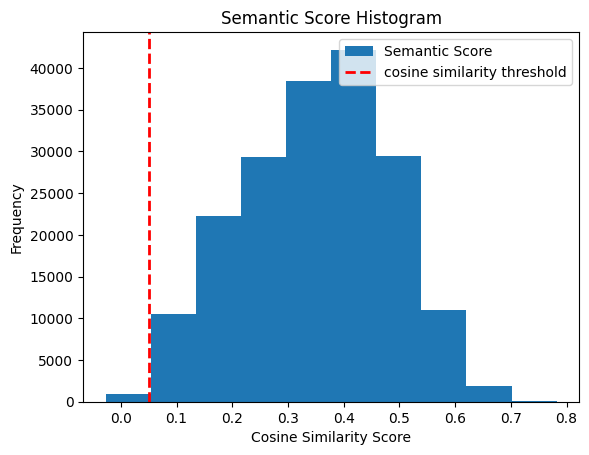

In [51]:
print(df_news_AI['semantic_score'].describe())
plt.hist(df_news_AI['semantic_score'], label='Semantic Score')
plt.title('Semantic Score Histogram')
plt.ylabel('Frequency')
plt.xlabel('Cosine Similarity Score')
plt.axvline(x=0.05, color='red', linestyle='dashed', linewidth=2, label='cosine similarity threshold')
plt.legend()
plt.show()

In [52]:
df_news_AI[(df_news_AI['semantic_score']>0.03) & (df_news_AI['semantic_score']<0.04)].sample(10)

,url,date,title,text,year,month,text_word_count,title_word_count,clean_title,clean_text,title_word_clean_count,text_word_clean_count,title_text_clean,title_text_clean_count,semantic_score
64925,https://www.wjhl.com/news/politics/ap-amazon-g...,2023-07-21,"Amazon, Google, Meta, Microsoft and other tech...","\n\n \n\nAmazon, Google, Meta, Microsoft and...",2023,7,1894,24,"Amazon, Google, Meta, Microsoft and other tech...",\nSkip to content\nWJHL | Tri-Cities News & We...,17,339,"Amazon, Google, Meta, Microsoft and other tech...",356,0.030888
158346,https://www.wate.com/automotive/internet-brand...,2024-01-09,2025 VW Golf teased at CES with integrated Cha...,\n\n \n\n \n2025 VW Golf teased at CES with ...,2024,1,1644,15,2025 VW Golf teased at CES with integrated Cha...,\nSkip to content\nWATE 6 On Your Side\nKnoxvi...,15,921,2025 VW Golf teased at CES with integrated Cha...,936,0.034991
190837,https://www.theprogress.com/news/privacy-bill-...,2022-06-16,Privacy bill would set out rules on use of per...,\nPrivacy bill would set out rules on use of p...,2022,6,1280,16,Privacy bill would set out rules on use of per...,\nSearchHome\nGood News\nNewsletters\nSubscrib...,16,1264,Privacy bill would set out rules on use of per...,1280,0.033613
146116,https://www.indiatoday.in/technology/news/stor...,2025-07-16,Meta AI had a privacy flaw that let users see ...,Meta AI had a privacy flaw that let users see ...,2025,7,936,24,Meta AI had a privacy flaw that let users see ...,Madhya Pradesh man rides bike with cobra wrapp...,21,131,Meta AI had a privacy flaw that let users see ...,152,0.031836
42710,https://www.mexc.co/en-IN/price/PALMAI/CUP,2025-12-10,PALMAI to CUP: Convert PaLM AI to Cuban Peso |...,PALMAI to CUP: Convert PaLM AI to Cuban Peso |...,2025,12,4093,17,PALMAI to CUP: Convert PaLM AI to Cuban Peso,ExchangeDEX+Buy CryptoMarketsSpotFutures500XEa...,9,4077,PALMAI to CUP: Convert PaLM AI to Cuban Peso E...,4086,0.035978
183261,https://www.valleycentral.com/news/tech-news/a...,2023-07-13,ChatGPT-maker OpenAI signs deal with AP to lic...,\n\n \n\nChatGPT-maker OpenAI signs deal wit...,2023,7,1552,12,ChatGPT-maker OpenAI signs deal with AP to lic...,\nSkip to content\nKVEO-TV\nBrownsville\n94°\n...,12,372,ChatGPT-maker OpenAI signs deal with AP to lic...,384,0.037938
148958,https://www.cranbrooktownsman.com/trending-now...,2022-02-01,Robots and AI being used to help combat COVID-...,\n\nRobots and AI being used to help combat CO...,2022,2,1253,16,Robots and AI being used to help combat COVID-...,\nSearchHome\nGood News\nCannabis\nSubmit News...,16,1056,Robots and AI being used to help combat COVID-...,1072,0.033296
53785,https://photofocus.com/software/skylum/how-to-...,2022-04-19,How to straighten horizon lines in Luminar AI ...,\nHow to straighten horizon lines in Luminar A...,2022,4,1109,12,How to straighten horizon lines in Luminar AI ...,\nBy\nJulie Powell\n0\nShare with\nyour friend...,10,419,How to straighten horizon lines in Luminar AI ...,429,0.037518
126032,https://www.newsbreak.com/news/2691457083509/a...,2022-08-06,A Breakthrough in Dementia Care: AI Can Diagno...,A Breakthrough in Dementia Care: AI Can Diagno...,2022,8,1405,15,A Breakthrough in Dementia Care: AI Can Diagno...,By Boston University School of Medicinescitech...,13,1295,A Breakthrough in Dementia Care: AI Can Diagno...,1308,0.039198
96225,https://www.gillettenewsrecord.com/obituaries/...,2023-01-26,Jerry Claude Shuck | Obituaries | gillettenews...,\nJerry Claude Shuck | Obituaries | gillettene...,2023,1,1623,7,Jerry Claude Shuck,", 78, died Monday, Jan. 23, 2023, surrounded b...",3,1410,"Jerry Claude Shuck , 78, died Monday, Jan. 23,...",1413,0.038353


In [53]:
df_news_AI.loc[58433,'clean_title']

"Apple is paying OpenAI for ChatGPT on iPhone with everyone's favorite currency: exposure"

In [54]:
df_news_AI.loc[58433,'clean_text'][0:500]

"\nNews\nBy James Bentley published 13 June 2024\n“The partnership isn't expected to generate meaningful revenue for either party — at least at the outset.”\nComments (0)\n(Image credit: Gerald Lynch / Future / Apple)\nWWDC 2024 was pretty huge, with announcements made for major upgrades to macOS Sequoia, iOS 18, and even some very good macOS gaming support. However, Apple Intelligence, and specifically Apple's adoption of OpenAI's ChatGPT was the biggest announcement — yet OpenAI is expected to make n"

In [55]:
# Filter out articles based on cosine similarity score, for example, keep articles with a score above 0.05
df_news_AI_2 = df_news_AI[df_news_AI['semantic_score'] > 0.00002]
filtered_rows_2 = df_news_AI_2.shape[0]
print('Number of rows before filtering:', original_rows)
print('Number of rows after filtering:', filtered_rows_2)
print('Number of rows removed {} , which represents {:.2%}'.format(original_rows - filtered_rows_2, (original_rows - filtered_rows_2) / original_rows))

Number of rows before filtering: 199989
Number of rows after filtering: 185986
Number of rows removed 14003 , which represents 7.00%


In [56]:
# Total filter rows
#df_news_AI = df_news_AI[df_news_AI['semantic_score'] > 0.05]
#filtered_rows_total = (original_rows - filtered_rows_1) + (original_rows-filtered_rows_2)
#print('Number of rows before filtering:', original_rows)
#print('Number of rows after filtering:', df_news_AI.shape[0])
#print('Number of rows removed {} , which represents {:.2%}'.format(filtered_rows_total, (filtered_rows_total) / original_rows))

In [57]:
# Filter the index in the dataframe
df_news_AI.reset_index(drop=True, inplace=True)

In [58]:
df_news_AI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186029 entries, 0 to 186028
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   url                     186029 non-null  object        
 1   date                    186029 non-null  datetime64[ns]
 2   title                   186029 non-null  object        
 3   text                    186029 non-null  object        
 4   year                    186029 non-null  int32         
 5   month                   186029 non-null  int32         
 6   text_word_count         186029 non-null  int64         
 7   title_word_count        186029 non-null  int64         
 8   clean_title             186029 non-null  object        
 9   clean_text              186029 non-null  object        
 10  title_word_clean_count  186029 non-null  int64         
 11  text_word_clean_count   186029 non-null  int64         
 12  title_text_clean        186029

In [ ]:
# Export data
df_news_AI.to_parquet(f'{DATA_DIR}/df_news_clean.parquet')